# Lab 2
### Guideline
1. Please submit the file via Google Classroom.
2. Provide your personal information in the next block.

### Student information
Full name: Bùi Ngọc Bảo Trân

Student ID: 25MS33062

Group: 2

In [68]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import requests

# define your addition imported libraries below

In [69]:
def download_input_data(url):
  print(f"Downloading from {url}")
  # Download the image.
  response = requests.get(url, stream=True)
  response.raise_for_status()

  # Read the image data from the response
  image_data = np.asarray(bytearray(response.content), dtype="uint8")

  # Decode the image using OpenCV
  img_color = cv.imdecode(image_data, cv.IMREAD_COLOR_RGB)

  return img_color

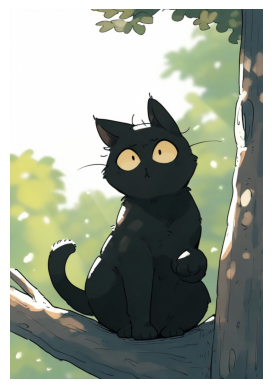

In [70]:
file_id = '1Tn-LUVbwk5pWz3r-mQPYqzb9VpJZivwu'
download_url = f'https://drive.google.com/uc?export=download&id={file_id}'
img_color = download_input_data(download_url)

plt.imshow(img_color)
plt.axis('off')
plt.show()

# Question 1 (35pts) - basic operation
Consider `img_color` is the input image. Let's perform and fulfill the below requests.

1.1. Print the basic properties of the image:
- Array shape, width, and height.
- Minimum, maximum, average, and standard deviation of pixel values for each color channel.

1.2. Display the input image alongside its intensity histograms for each individual color channel (R, G, B) and its overall lightness (grayscale) channel.

1.3. Invert the lightness of the input image, then repeat the visualization from step 1.2.

1.4. Convert the input image into a pencil sketch effect and display the result.
Note: The final output must use a white background and be cleaned without trivial details.

In [71]:
# 1.1 Print image properties:

H, W, C = img_color.shape

print("Image properties")
print(f"Shape  : {img_color.shape}")
print(f"Width  : {W}")
print(f"Height : {H}")

channel_names = ['Red', 'Green', 'Blue']

for i, name in enumerate(channel_names):
    channel = img_color[:, :, i]

    print(f"\n{name} channel")
    print(f"Min  : {channel.min()}")
    print(f"Max  : {channel.max()}")
    print(f"Mean : {channel.mean():.2f}")
    print(f"Std  : {channel.std():.2f}")

Image properties
Shape  : (1216, 832, 3)
Width  : 832
Height : 1216

Red channel
Min  : 0
Max  : 255
Mean : 139.09
Std  : 91.17

Green channel
Min  : 0
Max  : 255
Mean : 147.32
Std  : 87.86

Blue channel
Min  : 0
Max  : 255
Mean : 132.81
Std  : 82.71


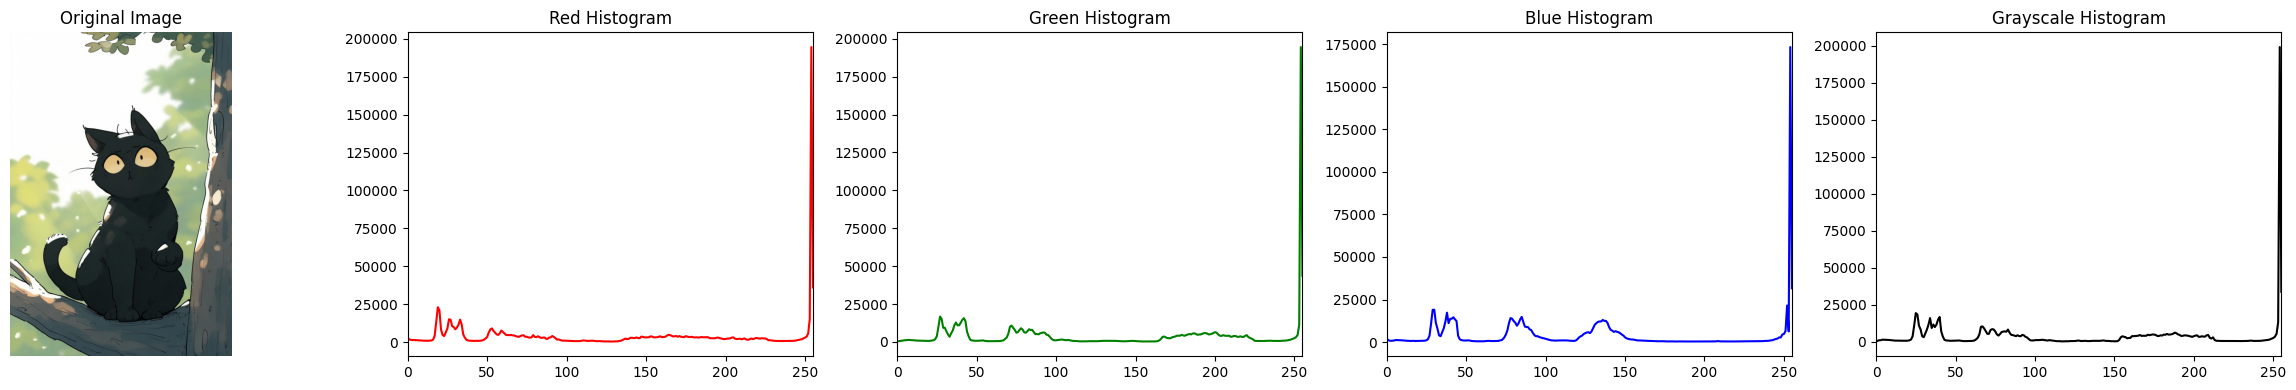

In [72]:
# 1.2. Display image and histograms:

gray = cv.cvtColor(img_color, cv.COLOR_RGB2GRAY)

fig, axes = plt.subplots(1, 5, figsize=(24, 4))

axes[0].imshow(img_color)
axes[0].set_title("Original Image")
axes[0].axis("off")

colors = ['r', 'g', 'b']
names = ['Red', 'Green', 'Blue']

for i in range(3):
    hist = cv.calcHist([img_color], [i], None, [256], [0, 256])

    axes[i + 1].plot(hist, color=colors[i])
    axes[i + 1].set_title(f"{names[i]} Histogram")
    axes[i + 1].set_xlim([0, 255])

gray_hist = cv.calcHist([gray], [0], None, [256], [0, 256])

axes[4].plot(gray_hist, color='black')
axes[4].set_title("Grayscale Histogram")
axes[4].set_xlim([0, 255])

# Display results
plt.tight_layout()
plt.show()

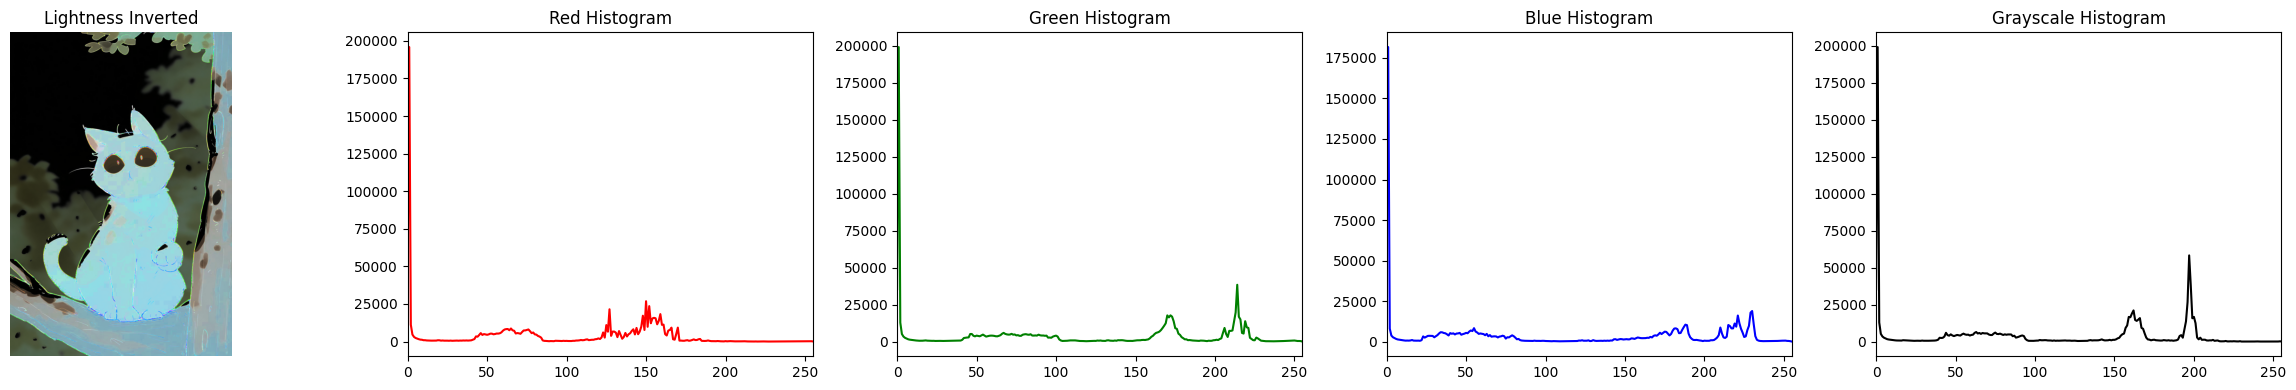

In [73]:
# 1.3. Invert lightness and show histograms:

gray = cv.cvtColor(img_color, cv.COLOR_RGB2GRAY)

gray_inv = 255 - gray

hsv = cv.cvtColor(img_color, cv.COLOR_RGB2HSV)

hsv[:, :, 2] = gray_inv

img_inverted_lightness = cv.cvtColor(
    hsv,
    cv.COLOR_HSV2RGB
)

gray_new = cv.cvtColor(
    img_inverted_lightness,
    cv.COLOR_RGB2GRAY
)

fig, axes = plt.subplots(1, 5, figsize=(24, 4))

axes[0].imshow(img_inverted_lightness)
axes[0].set_title("Lightness Inverted")
axes[0].axis("off")

colors = ['r', 'g', 'b']
names = ['Red', 'Green', 'Blue']

for i in range(3):
    hist = cv.calcHist(
        [img_inverted_lightness],
        [i],
        None,
        [256],
        [0, 256]
    )

    axes[i + 1].plot(hist, color=colors[i])
    axes[i + 1].set_title(f"{names[i]} Histogram")
    axes[i + 1].set_xlim([0, 255])

gray_hist = cv.calcHist(
    [gray_new],
    [0],
    None,
    [256],
    [0, 256]
)

axes[4].plot(gray_hist, color='black')
axes[4].set_title("Grayscale Histogram")
axes[4].set_xlim([0, 255])

# Display results
plt.tight_layout()
plt.show()

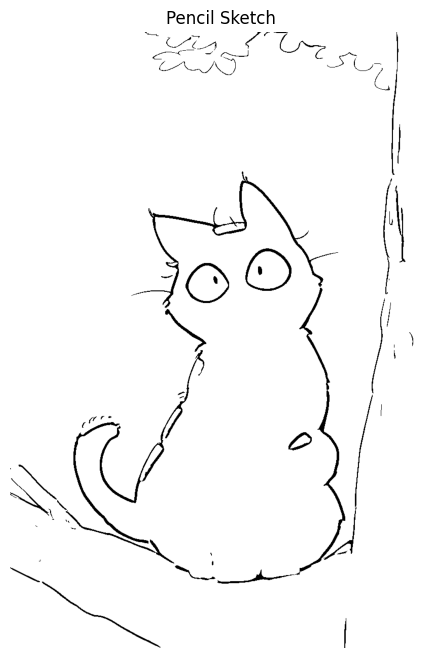

In [74]:
# 1.4. Pencil sketch effect

gray = cv.cvtColor(
    img_color,
    cv.COLOR_RGB2GRAY
)

gray = cv.bilateralFilter(
    gray,
    d=9,
    sigmaColor=75,
    sigmaSpace=75
)

inv = 255 - gray

blur = cv.GaussianBlur(
    inv,
    (21, 21),
    0
)

sketch = cv.divide(
    gray,
    255 - blur,
    scale=256
)

sketch = cv.fastNlMeansDenoising(
    sketch,
    None,
    15,
    7,
    21
)

_, sketch = cv.threshold(
    sketch,
    180,
    255,
    cv.THRESH_BINARY
)

# Display results
plt.figure(figsize=(8, 8))
plt.imshow(sketch, cmap='gray')
plt.title("Pencil Sketch")
plt.axis("off")
plt.show()

# Question 2 (35+pts)
Consider `img_color` is the input image. Comlete the following tasks.

2.1. Resize the input image to 1024×1024 pixels. Divide the image into an 8×8 grid of 64 equal-sized blocks. Label each block with its corresponding grid index, reconstruct (concatenate) the blocks back into a 1024×1024 image, and display the output.

2.2. Calculate the average lightness of each block. Reorder the 64 blocks in ascending order of their average lightness, concatenate them back into a 1024×1024 image, and display the output.

2.3. (Optional) Do you observe blocking artifacts in the output of step 2.2? Explain why they occur. If artifacts are present, propose and implement an optimized solution to mitigate or remove them.

2.4. Randomly select one block from the 64 blocks. Find the six most visually similar blocks to it within the image. Dim (reduce the brightness of) all other blocks except for the selected block and its six closest matches. Display the final reconstructed image.

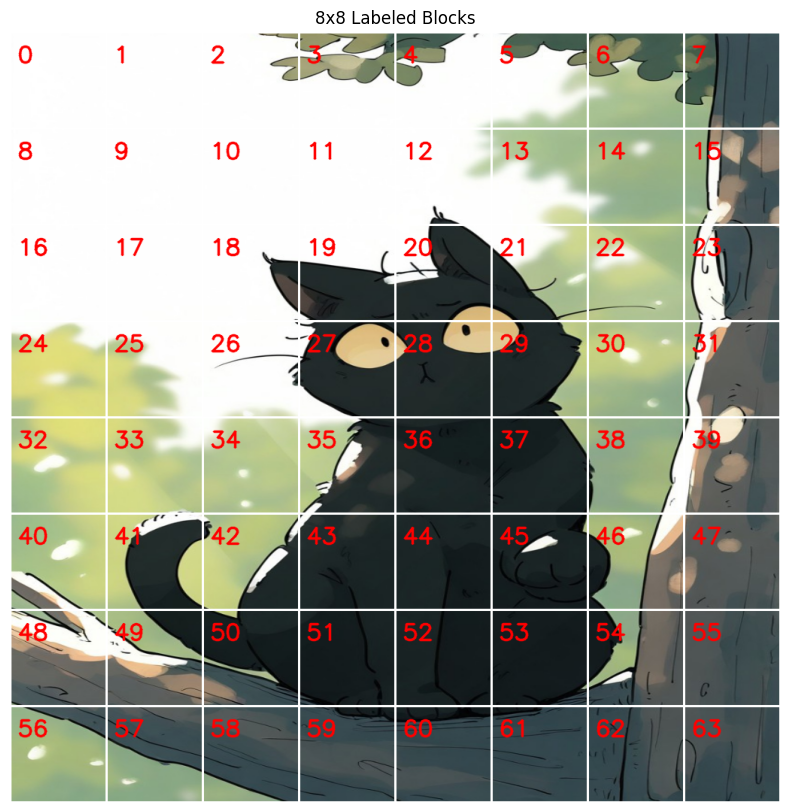

In [75]:
# 2.1. Resize -> split into 8x8 blocks -> label -> reconstruct:

img_1024 = cv.resize(img_color, (1024, 1024))

block_size = 1024 // 8

blocks = []

for r in range(8):
    row_blocks = []

    for c in range(8):

        y1 = r * block_size
        y2 = (r + 1) * block_size

        x1 = c * block_size
        x2 = (c + 1) * block_size

        block = img_1024[y1:y2, x1:x2].copy()

        idx = r * 8 + c

        cv.putText(
            block,
            str(idx),
            (10, 40),
            cv.FONT_HERSHEY_SIMPLEX,
            1,
            (255, 0, 0),
            2,
            cv.LINE_AA
        )

        row_blocks.append(block)

    blocks.append(row_blocks)

reconstructed = np.vstack(
    [np.hstack(row) for row in blocks]
)

# White grid
for i in range(9):

    pos = i * block_size

    cv.line(
        reconstructed,
        (0, pos),
        (1024, pos),
        (255, 255, 255),
        2
    )

    cv.line(
        reconstructed,
        (pos, 0),
        (pos, 1024),
        (255, 255, 255),
        2
    )

# Display results
plt.figure(figsize=(10,10))
plt.imshow(reconstructed)
plt.axis("off")
plt.title("8x8 Labeled Blocks")
plt.show()

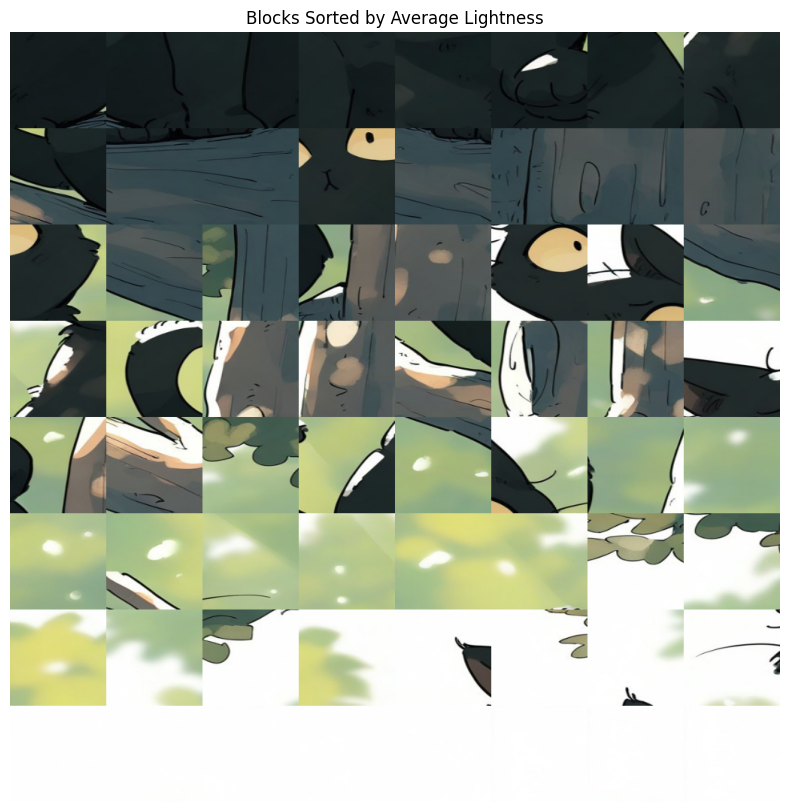

In [76]:
# 2.2. Sort blocks by average lightness

img_1024 = cv.resize(img_color, (1024, 1024))

block_size = 128

block_list = []

for r in range(8):
    for c in range(8):

        y1 = r * block_size
        y2 = (r + 1) * block_size

        x1 = c * block_size
        x2 = (c + 1) * block_size

        block = img_1024[y1:y2, x1:x2].copy()

        gray = cv.cvtColor(
            block,
            cv.COLOR_RGB2GRAY
        )

        mean_lightness = gray.mean()

        block_list.append(
            (mean_lightness, block)
        )

block_list.sort(key=lambda x: x[0])

sorted_blocks = [x[1] for x in block_list]

rows = []

for i in range(8):
    rows.append(
        np.hstack(sorted_blocks[i*8:(i+1)*8])
    )

sorted_image = np.vstack(rows)

# Display results
plt.figure(figsize=(10,10))
plt.imshow(sorted_image)
plt.axis("off")
plt.title("Blocks Sorted by Average Lightness")
plt.show()

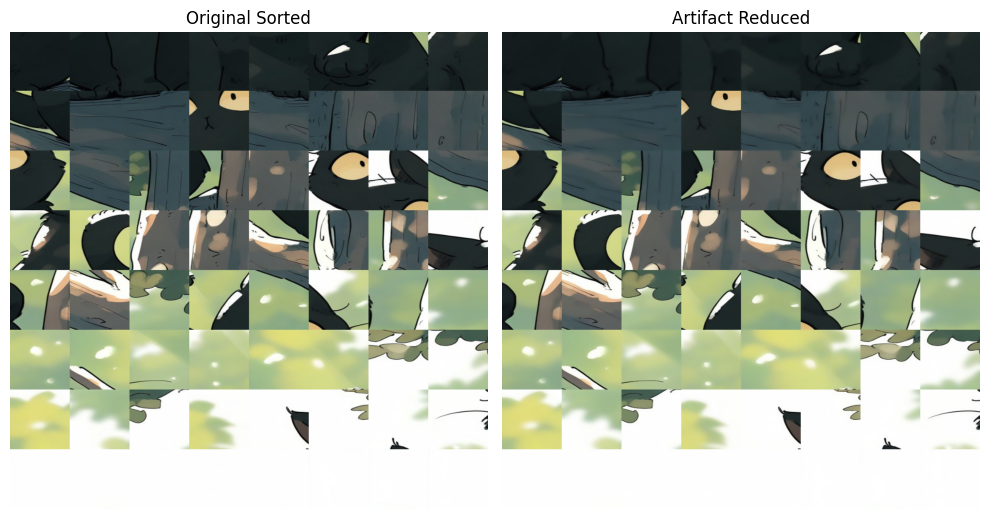

In [77]:
# 2.3. Reduce blocking artifacts

smoothed = cv.bilateralFilter(
    sorted_image,
    d=9,
    sigmaColor=50,
    sigmaSpace=50
)

# Display results
plt.figure(figsize=(10,10))

plt.subplot(1,2,1)
plt.imshow(sorted_image)
plt.axis("off")
plt.title("Original Sorted")

plt.subplot(1,2,2)
plt.imshow(smoothed)
plt.axis("off")
plt.title("Artifact Reduced")

plt.tight_layout()
plt.show()

**Giải thích:**

Blocking artifacts xuất hiện vì:

- Các block được sắp xếp lại nhưng biên block vẫn giữ nguyên.
- Hai block kề nhau có thể đến từ những vùng hoàn toàn khác nhau trong ảnh.
- Sự thay đổi đột ngột ở biên tạo cảm giác "vá chắp" (patchwork).

Bilateral filter giúp làm mượt biên mà vẫn giữ được cấu trúc chính của ảnh.

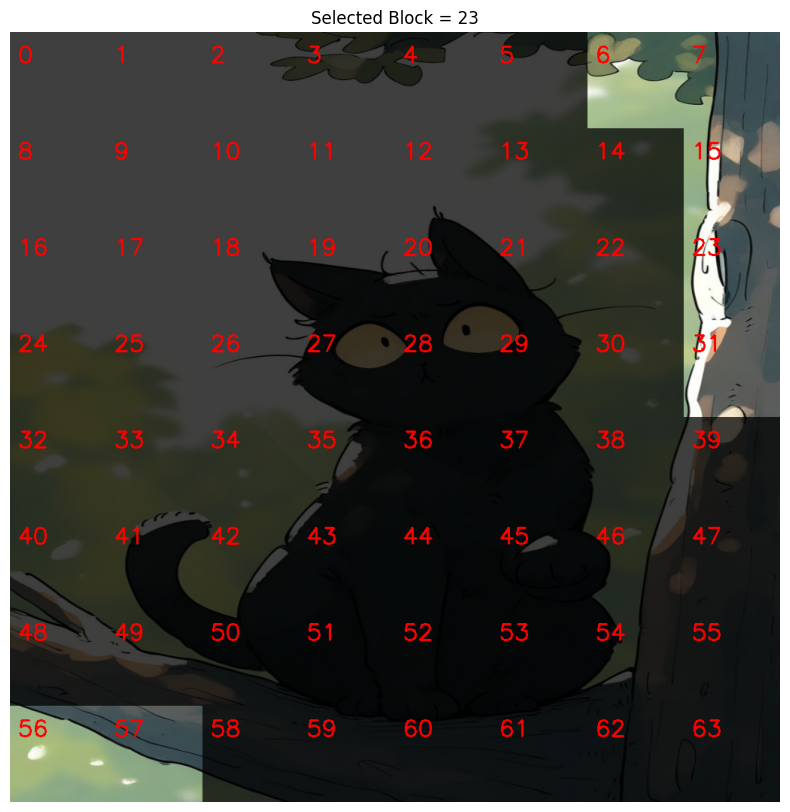

Selected block: 23
6 closest blocks: [15, 31, 57, 6, 56, 7]


In [78]:
# 2.4. Random block + 6 most similar blocks

img_1024 = cv.resize(img_color, (1024, 1024))

block_size = 128

blocks = []

for r in range(8):
    for c in range(8):

        y1 = r * block_size
        y2 = (r + 1) * block_size

        x1 = c * block_size
        x2 = (c + 1) * block_size

        block = img_1024[y1:y2, x1:x2]

        blocks.append(block)

features = []

for block in blocks:

    small = cv.resize(block, (32, 32))

    feat = small.flatten().astype(np.float32)

    features.append(feat)

features = np.array(features)

query_idx = np.random.randint(64)

query_feature = features[query_idx]

distances = np.linalg.norm(
    features - query_feature,
    axis=1
)

nearest = np.argsort(distances)[1:7]

keep_indices = set(
    [query_idx] + nearest.tolist()
)

new_blocks = []

for i, block in enumerate(blocks):

    block_copy = block.copy()

    if i not in keep_indices:

        block_copy = (
            block_copy.astype(np.float32) * 0.25
        ).astype(np.uint8)

    cv.putText(
        block_copy,
        str(i),
        (10, 40),
        cv.FONT_HERSHEY_SIMPLEX,
        1,
        (255, 0, 0),
        2
    )

    new_blocks.append(block_copy)

rows = []

for i in range(8):
    rows.append(
        np.hstack(new_blocks[i*8:(i+1)*8])
    )

result = np.vstack(rows)

# Display results
plt.figure(figsize=(10,10))
plt.imshow(result)
plt.axis("off")
plt.title(
    f"Selected Block = {query_idx}"
)
plt.show()

print("Selected block:", query_idx)
print("6 closest blocks:", nearest.tolist())

# Question 3 (30pts)

3.1. Optimize the provided input image (representing an old, degraded document), [here](https://drive.google.com/file/d/1sAymBt2u1gFKU-lBqTeFSX94Ie3fg90F/view?usp=share_link), to improve readability and contrast, using the provided [reference image](https://drive.google.com/file/d/1JWLnKCkSADh2yR3BMmJu05rmho1R2Jrf/view?usp=share_link) as a target baseline. Higher quality outputs that surpass the baseline are encouraged. Let's display your enhanced result side-by-side with the original input and briefly explain your solution with explaination.

3.2. Embed your name as a visible digital central watermark onto the optimized document generated in step 3.1. Display the final watermarked image.

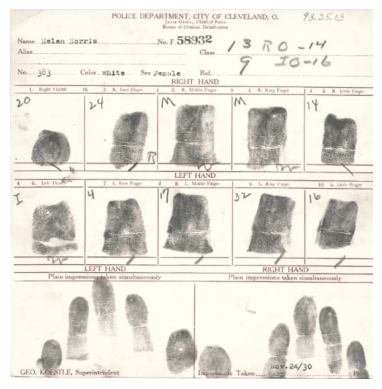

In [79]:
file_id = "1sAymBt2u1gFKU-lBqTeFSX94Ie3fg90F"
download_url = f"https://drive.google.com/uc?export=download&id={file_id}"

img_doc = download_input_data(download_url)

plt.imshow(img_doc)
plt.axis("off")
plt.show()

Enhanced shape: (1136, 1114)  dtype: uint8

── Quality Metrics ─────────────────────────────────────────
  Input       │ Sharpness (Lap.var):      213.5 │ RMS Contrast:  42.53
  Enhanced    │ Sharpness (Lap.var):   20,744.1 │ RMS Contrast:  84.28
──────────────────────────────────────────────────────────────


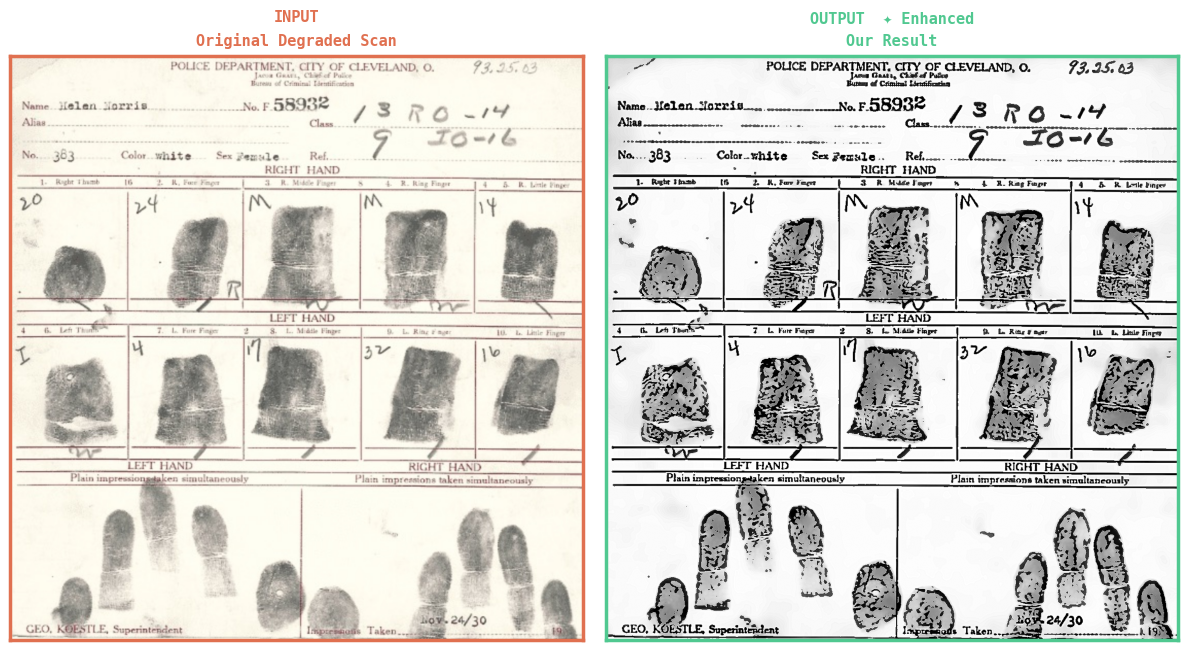

In [80]:
# 3.1. Enhance picture:
from PIL import Image
from io import BytesIO

def download_input_data(url: str) -> np.ndarray:
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    img_pil = Image.open(BytesIO(resp.content)).convert("RGB")
    return np.array(img_pil)

def enhance_document(img_rgb: np.ndarray) -> np.ndarray:
    gray = cv.cvtColor(img_rgb, cv.COLOR_RGB2GRAY)

    denoised = cv.fastNlMeansDenoising(
        gray, h=10, templateWindowSize=7, searchWindowSize=21
    )

    clahe    = cv.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    clahe_img = clahe.apply(denoised)

    blur      = cv.GaussianBlur(clahe_img, (0, 0), sigmaX=2.0)
    sharpened = cv.addWeighted(clahe_img, 1.6, blur, -0.6, 0)

    adaptive  = cv.adaptiveThreshold(
        sharpened, 255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY,
        blockSize=25, C=8,
    )

    blended   = cv.addWeighted(sharpened, 0.55, adaptive, 0.45, 0)

    p2, p98   = np.percentile(blended, [2, 98])
    stretched = np.clip(
        (blended.astype(np.float32) - p2) / (p98 - p2) * 255,
        0, 255
    ).astype(np.uint8)

    kernel    = np.array([[  0, -0.3,   0],
                          [-0.3,  2.2, -0.3],
                          [  0, -0.3,   0]], dtype=np.float32)
    final     = np.clip(cv.filter2D(stretched, -1, kernel), 0, 255).astype(np.uint8)

    return final

# Display results
enhanced = enhance_document(img_doc)
print(f"Enhanced shape: {enhanced.shape}  dtype: {enhanced.dtype}")

def metrics(gray: np.ndarray, label: str):
    lap_var = cv.Laplacian(gray, cv.CV_64F).var()
    rms_con = float(gray.std())
    print(f"  {label:12s}│ Sharpness (Lap.var): {lap_var:>10,.1f} "
          f"│ RMS Contrast: {rms_con:>6.2f}")

input_gray = cv.cvtColor(img_doc, cv.COLOR_RGB2GRAY)

print("\n── Quality Metrics ─────────────────────────────────────────")
metrics(input_gray, "Input")
metrics(enhanced,   "Enhanced")
print("─" * 62)

fig = plt.figure(figsize=(18, 7), facecolor="#FFFFFF")
gs  = gridspec.GridSpec(
    1, 3, figure=fig,
    wspace=0.04, left=0.01, right=0.99, top=0.88, bottom=0.02
)

panels = [
    (img_doc,  "INPUT\nOriginal Degraded Scan",   "#e07050"),
    (enhanced, "OUTPUT  ✦ Enhanced\nOur Result",    "#50c890"),
]

for col, (img, title, accent) in enumerate(panels):
    ax = fig.add_subplot(gs[col])
    cmap = "gray" if img.ndim == 2 else None
    ax.imshow(img, cmap=cmap)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(accent); spine.set_linewidth(2.5)
    ax.set_title(title, color=accent, fontsize=11,
                 fontfamily="monospace", fontweight="bold",
                 pad=8, linespacing=1.6)
plt.show()

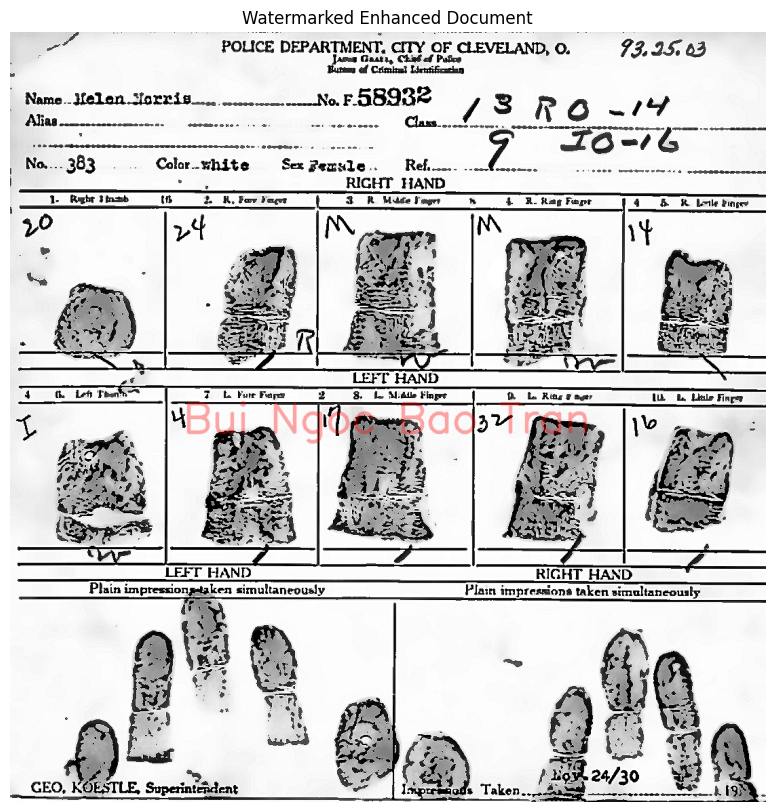

In [81]:
# 3.2. Write name on the result of 3.1:
optimized = enhance_document(img_doc)

watermarked = cv.cvtColor(optimized, cv.COLOR_GRAY2RGB)
name = "Bui Ngoc Bao Tran"
overlay = watermarked.copy()
font = cv.FONT_HERSHEY_SIMPLEX
font_scale = 2.0
thickness = 4

(text_w, text_h), _ = cv.getTextSize(name, font, font_scale, thickness)
x = (watermarked.shape[1] - text_w) // 2
y = (watermarked.shape[0] + text_h) // 2

cv.putText(overlay, name, (x, y), font, font_scale, (255, 0, 0), thickness, cv.LINE_AA)
alpha = 0.35
watermarked = cv.addWeighted(overlay, alpha, watermarked, 1 - alpha, 0)

# Display results
plt.figure(figsize=(10, 10))
plt.imshow(watermarked)
plt.axis("off")
plt.title("Watermarked Enhanced Document")
plt.show()